In [18]:
import numpy as np
import math 
import random
import scipy.stats as stats
import matplotlib.pyplot as plt

In [19]:
def walk_sim(N_sim, N, mu, T, sigma, X_init):
    # N_sim - number of simulations
    # N - number of timesteps
    # mu - drift
    # T - expiry time
    # sigma - volatility
    # X_init - initial value
    
    delt = T/N
    up = sigma*math.sqrt(delt)
    down = -sigma*math.sqrt(delt)
    
    p = 1./2.*(1. + mu/sigma*math.sqrt(delt))
    
    X_new = np.ones(N_sim)*X_init
    
    ptest = np.zeros(N_sim)
    
    for i in np.arange(N): #important that this is vectorized, per the instructions
        ptest = np.random.uniform(0,1,N_sim)
        ptest = (ptest < p)
        X_new = X_new + ptest*up + (1-ptest)*down
    
    return X_new

In [20]:
def gather_stats(outcomes, N, alpha, T, sigma, X_init):
    
    mean_val = np.mean(outcomes)
    print('Observed Mean = ' + str(mean_val))
    std_val = np.std(outcomes)
    print('Observed Standard deviation = ' + str(std_val))
    
    print('Theoretical Mean = ' + str(X_init+alpha*T))
    print('Theoretical Standard deviation = ' + str(sigma*math.sqrt(T)))
    
    dt = T/N
    min_val = X_init - N*sigma*math.sqrt(dt)
    max_val = X_init + N*sigma*math.sqrt(dt)
    binwidth = (max_val - min_val)/N
    bins = np.zeros(N+1)
    
    #non-vectorized
    #for sim in np.arange(sim_count): 
    #    X = outcomes[sim]
    #    bin_no = int(round(N*(X - min_val) / (max_val - min_val)))
    #    bins[bin_no] = bins[bin_no] + 1
    
    #vectorized - careful of the min/max ranges to get the right result
    binwidth = (max_val - min_val)/N
    bins, bin_edges = np.histogram(outcomes, bins=N+1, range = (min_val-0.5*binwidth,max_val+0.5*binwidth))
    
    
    #non-vectorized
    #bin_midpoints = np.zeros(N+1)
    #for i in np.arange(N+1):
    #    bin_midpoints[i] = min_val + (i-1)*binwidth
    
    #vectorized
    bin_midpoints = bin_edges + 0.5*binwidth
    bin_midpoints = bin_midpoints[:N+1]
    bins = bins / sim_count / binwidth
    
    #construct "true" PDF
    x = np.linspace(min_val,max_val, 1000)
    y = stats.norm.pdf(x, X_init+alpha*T, sigma*math.sqrt(T))
    
    #plot both together
    plt.bar(bin_midpoints,bins,width=binwidth)
    plt.plot(x,y,'r')
    
    plt.xlabel("X(T) Value")
    plt.ylabel("Probability Density")
    
    #form the plot using hist directly instead, also valid, if done correctly.
    #dummy = plt.hist(outcomes, density=True, bins=N+1, range = (min_val-0.5*binwidth,max_val+0.5*binwidth))

Observed Mean = 17.68101657402743
Observed Standard deviation = 0.4005487809243982
Theoretical Mean = 17.7
Theoretical Standard deviation = 0.3968626966596886


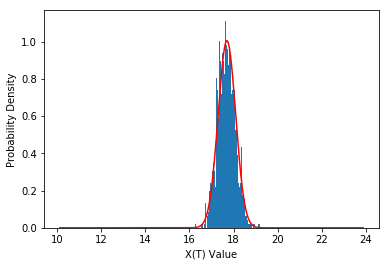

In [21]:
#parameters from Table 1
T = 1.75
sigma = 0.3
alpha = 0.4
X_init = 17
N = 300

sim_count = 1000

outcomes = walk_sim(sim_count, N, alpha, T, sigma, X_init)
gather_stats(outcomes, N, alpha, T, sigma, X_init)

Observed Mean = 17.699740978317028
Observed Standard deviation = 0.39622539452188205
Theoretical Mean = 17.7
Theoretical Standard deviation = 0.3968626966596886


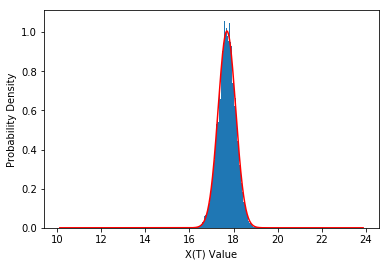

In [22]:
sim_count = 10000

outcomes = walk_sim(sim_count, N, alpha, T, sigma, X_init)
gather_stats(outcomes, N, alpha, T, sigma, X_init)

Observed Mean = 17.698605874317384
Observed Standard deviation = 0.3951809552209355
Theoretical Mean = 17.7
Theoretical Standard deviation = 0.3968626966596886


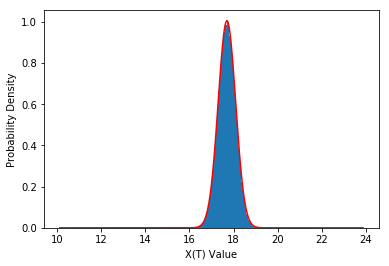

In [23]:
sim_count = 100000

outcomes = walk_sim(sim_count, N, alpha, T, sigma, X_init)
gather_stats(outcomes, N, alpha, T, sigma, X_init)

Observations: As we run more simulations (1000, 10000, 100000), the observed histogram is visually converging to match the PDF, with less apparent noise compared to the true curve. The mean and std deviation are already in roughly the expected neighborhood, even for just 100 simulations. Basic observations along these lines are what I'm expecting.




(Note that while the stats start off reasonably close, we would ultimately need to also reduce the time step size to see true convergence in the numbers, for both mean and std dev. But students don't need to comment on this.)